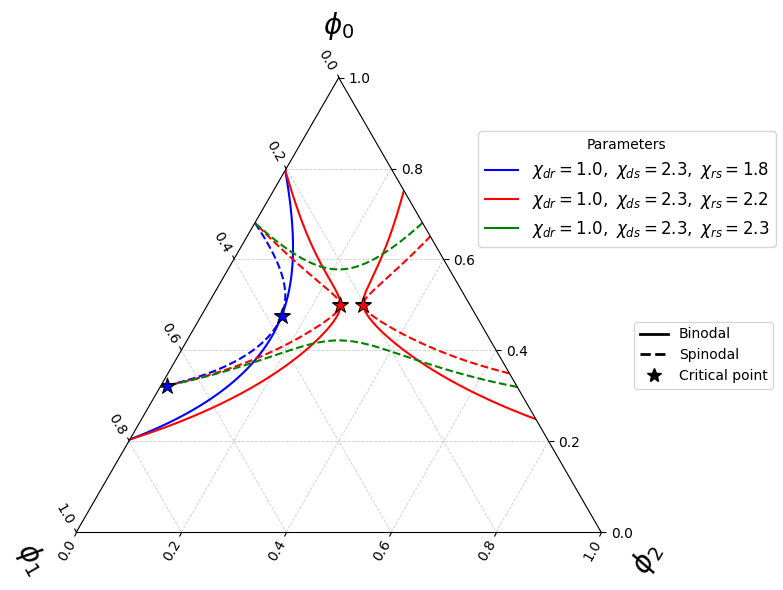

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import mpltern
import networkx as nx
from pyphasediagram.diagram import PhaseDiagram
from matplotlib.lines import Line2D


def _to_ternary(phi1, phi2):
    ''' 
    Helper function to compute the volume fraction of the third component
    '''
    phi1 = np.asarray(phi1)
    phi2 = np.asarray(phi2)
    phi0 = 1.0 - phi1 - phi2
    return phi0, phi1, phi2


def make_2x2_chi(chi_dr=2.8, chi_ds=2.8, chi_rs=2.8):
    chi_11 = -2 * chi_ds
    chi_22 = -2 * chi_rs
    chi_12 = chi_dr - chi_rs - chi_ds

    return np.array([
        [chi_11, chi_12],
        [chi_12, chi_22]
    ])


def build_phase_diagram(chi_dr, chi_ds, chi_rs):
    chi_matrix = make_2x2_chi(
        chi_dr=chi_dr,
        chi_ds=chi_ds,
        chi_rs=chi_rs
    )

    diagram = PhaseDiagram(chi_matrix)
    diagram.build()

    return diagram


def plot_multiple_phase_diagrams(parameter_sets, colors=[]):
    """
    Overlay multiple binodal and spinodal phase diagrams
    on the same ternary axes.

    parameter_sets: list of dictionaries, e.g.

        [
            {"chi_dr": 1.0, "chi_ds": 2.3, "chi_rs": 1.0},
            {"chi_dr": 1.0, "chi_ds": 2.5, "chi_rs": 1.0},
            {"chi_dr": 1.0, "chi_ds": 2.8, "chi_rs": 1.0},
        ]
    """
    if len(colors) == 0:
        colors = plt.cm.rainbow(np.linspace(0.05, 0.8, len(parameter_sets)))

    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection="ternary")

    ax.set_tlabel(r"$\phi_0$", fontsize=20)
    ax.set_llabel(r"$\phi_1$", fontsize=20)
    ax.set_rlabel(r"$\phi_2$", fontsize=20)

    ax.grid(
        True,
        color="0.8",
        linestyle="--",
        linewidth=0.6
    )

    legend_handles = []

    for color, params in zip(colors, parameter_sets):

        diagram = build_phase_diagram(
            chi_dr=params["chi_dr"],
            chi_ds=params["chi_ds"],
            chi_rs=params["chi_rs"]
        )

        label = (
            rf"$\chi_{{dr}}={params['chi_dr']:.1f},\ "
            rf"\chi_{{ds}}={params['chi_ds']:.1f},\ "
            rf"\chi_{{rs}}={params['chi_rs']:.1f}$"
        )

        
        # Spinodal curves
        
        for component in nx.connected_components(
            diagram.spinodal.spinodal_graph
        ):
            sg = diagram.spinodal.spinodal_graph.subgraph(component)

            phi1s, phi2s = (
                diagram.spinodal._coords_from_subgraph(sg)
            )

            t0, t1, t2 = _to_ternary(phi1s, phi2s)

            ax.plot(
                t0, t1, t2,
                color=color,
                linestyle="--",
                linewidth=1.5
            )

       
        # Binodal curves
       
        for section in diagram.binodal.binodal_sections:

            for branch in range(2):

                phi1s = section.phis[branch, 0]
                phi2s = section.phis[branch, 1]

                t0, t1, t2 = _to_ternary(phi1s, phi2s)

                ax.plot(
                    t0, t1, t2,
                    color=color,
                    linestyle="-",
                    linewidth=1.5
                )

        
        # Three-phase vertices
        
        if diagram.binodal.three_phase_polygons is not None:

            for poly in diagram.binodal.three_phase_polygons:

                coords = np.asarray(poly.exterior.coords)

                # Remove repeated closing point
                phi1s = coords[:-1, 0]
                phi2s = coords[:-1, 1]

                t0, t1, t2 = _to_ternary(phi1s, phi2s)

                ax.scatter(
                    t0, t1, t2,
                    color=color,
                    s=45,
                    edgecolor="black",
                    linewidth=0.5,
                    zorder=5
                )

        
        # Critical points
        
        for cp in diagram.spinodal.critical_points:

            t0, t1, t2 = _to_ternary(
                cp.phi1,
                cp.phi2
            )

            ax.scatter(
                [t0], [t1], [t2],
                color=color,
                marker="*",
                edgecolor="black",
                linewidth=0.7,
                s=150,
                zorder=6
            )

        # One legend entry per parameter set
        legend_handles.append(
            Line2D(
                [0], [0],
                color=color,
                linewidth=1.5,
                label=label
            )
        )

    # Separate legend explaining line styles
    style_handles = [
        Line2D(
            [0], [0],
            color="black",
            linestyle="-",
            linewidth=2,
            label="Binodal"
        ),
        Line2D(
            [0], [0],
            color="black",
            linestyle="--",
            linewidth=2,
            label="Spinodal"
        ),
        Line2D(
            [0], [0],
            color="black",
            marker="*",
            linestyle="None",
            markersize=10,
            label="Critical point"
        )
    ]

    parameter_legend = ax.legend(
        handles=legend_handles,
        title="Parameters",
        loc="upper left",
        bbox_to_anchor=(0.75, 0.9), fontsize=12
    )

    ax.add_artist(parameter_legend)

    ax.legend(
        handles=style_handles,
        loc="lower left",
        bbox_to_anchor=(1.05, 0.3)
    )

    fig.tight_layout()

    return fig, ax

parameter_sets = [
    {
        "chi_dr": 1.0,
        "chi_ds": 2.3,
        "chi_rs": 1.8
    },
    
    {
        "chi_dr": 1.0,
        "chi_ds": 2.3,
        "chi_rs": 2.2
    },
    
    {
        "chi_dr": 1.0,
        "chi_ds": 2.3,
        "chi_rs": 2.3
    }, 
    
]

fig, ax = plot_multiple_phase_diagrams(parameter_sets, colors=['b','r','g'])
plt.tight_layout()
#plt.savefig('param_chi_rs.svg',dpi=300)
plt.show()